In [2]:
import pandas as pd
import seaborn as sns
import matplotlib
matplotlib.use("Agg") 
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import sqlite3
from threading import Thread

cnx = sqlite3.connect('../data.db')
try:
    cnx.execute('''
            CREATE INDEX IF NOT EXISTS idx_elasticity_lookup 
            ON data (experiment, provider, date_time, language, cpu, memory, timestamp)
    ''')
    cnx.commit()
    print("Index created/verified")
except Exception as e:
    print(f"Index creation note: {e}")

Index created/verified


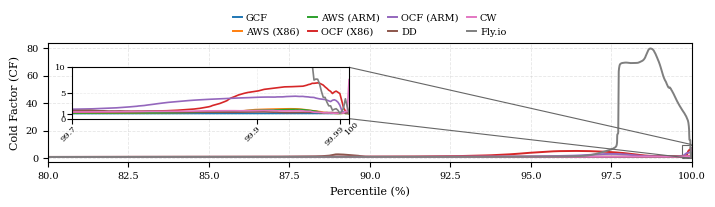


Absolute Latencies & Cold Factor (CF) per Percentile (99 to 100, 0.05 steps)

--- GCF ---
 Percentile  Warm Latency  All Latency  Cold Factor
      99.00       110.091      110.173        1.001
      99.05       111.845      111.954        1.001
      99.10       113.714      113.804        1.001
      99.15       115.778      115.874        1.001
      99.20       117.749      117.858        1.001
      99.25       119.598      119.689        1.001
      99.30       121.388      121.493        1.001
      99.35       123.256      123.359        1.001
      99.40       125.136      125.239        1.001
      99.45       127.167      127.273        1.001
      99.50       129.127      129.208        1.001
      99.55       131.047      131.168        1.001
      99.60       132.868      132.959        1.001
      99.65       134.660      134.763        1.001
      99.70       136.633      136.726        1.001
      99.75       138.490      138.567        1.001
      99.80       140.262

In [3]:
# Line plot: ratio vs percentile (better highlights p99.9 vs p99.99 behavior)
import numpy as np
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# Optional re-imports (keeps this cell runnable standalone, relying only on Cell 1 for cnx)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Paper-friendly styling (ACM Middleware 2-column format)
# 3.33 inches is the standard single-column width. 
# Fonts are set between 7pt and 8pt to match the paper's body text scale.
plt.rcParams.update({
    'font.size': 8,
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'font.family': 'serif', # Often preferred for ACM/IEEE papers
})

if "cnx" not in globals() or cnx is None:
    raise RuntimeError("Missing database connection `cnx`. Run Cell 1 first.")

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]

label_map = {
    "google": "GCF",
    "awsX86": "AWS (X86)",
    "awsARM": "AWS (ARM)",
    "oracleX86": "OCF (X86)",
    "oracleARM": "OCF (ARM)",
    "deno": "DD",
    "cloudflare": "CW",
    "flyio": "Fly.io",
    "fastly": "Fastly" # Keeping fastly capitalized as a fallback
}

def load_warmstart(provider: str, mode: str) -> pd.DataFrame:
    """Load warmstart latencies for a provider.

    mode='cold0' -> filter cold_starts=0
    mode='all'   -> no cold_starts filter
    """
    if mode == "cold0":
        query = """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        """
        return pd.read_sql_query(query, cnx, params=[provider])

    query = """
        SELECT http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'warmstart'
    """
    return pd.read_sql_query(query, cnx, params=[provider])

# Keep linspace parameters consistent with other cold-impact cells.
percentiles = np.linspace(0.80, 1.00, 10000)  # 80th..100th percentile for the curve
table_percentiles = np.linspace(0.99, 1.00, 21) # Exact 99, 99.05, ..., 100 for the table

rows_curve = []
rows_table = []

for provider in providers:
    df_cold0 = load_warmstart(provider, "cold0")
    df_all = load_warmstart(provider, "all")

    for frame in (df_cold0, df_all):
        frame["http_req_waiting"] = pd.to_numeric(frame["http_req_waiting"], errors="coerce")

    df_cold0 = df_cold0.dropna(subset=["http_req_waiting"])
    df_all = df_all.dropna(subset=["http_req_waiting"])
    df_cold0 = df_cold0[df_cold0["http_req_waiting"] > 0]
    df_all = df_all[df_all["http_req_waiting"] > 0]

    if df_cold0.empty or df_all.empty:
        continue

    # 1. Calculate for the high-res plot
    q_cold0 = df_cold0["http_req_waiting"].quantile(percentiles).to_numpy()
    q_all = df_all["http_req_waiting"].quantile(percentiles).to_numpy()
    ratio_curve = q_all / q_cold0
    ratio_curve = np.where(np.isfinite(ratio_curve), ratio_curve, np.nan)

    for p, r in zip(percentiles, ratio_curve):
        rows_curve.append({"provider": provider, "percentile": float(p) * 100.0, "ratio": float(r)})

    # 2. Calculate specifically for the 99-100 table
    q_cold0_tbl = df_cold0["http_req_waiting"].quantile(table_percentiles).to_numpy()
    q_all_tbl = df_all["http_req_waiting"].quantile(table_percentiles).to_numpy()
    ratio_tbl = q_all_tbl / q_cold0_tbl
    ratio_tbl = np.where(np.isfinite(ratio_tbl), ratio_tbl, np.nan)
    
    # Store absolute values as well as the calculated factor
    for p, r, w, a in zip(table_percentiles, ratio_tbl, q_cold0_tbl, q_all_tbl):
        rows_table.append({
            "Provider": label_map.get(provider, provider),
            "Percentile": round(p * 100.0, 2),
            "Warm Latency": float(w),
            "All Latency": float(a),
            "Cold Factor": float(r)
        })

df_curve = pd.DataFrame(rows_curve).dropna(subset=["ratio"])

if df_curve.empty:
    print("No data to plot ratio vs percentile.")
else:
    providers_in_plot = [p for p in providers if p in set(df_curve["provider"]) ]
    palette = sns.color_palette("tab10", n_colors=len(providers_in_plot))
    palette_map = dict(zip(providers_in_plot, palette))

    # ACM full-page (two-column) width is ~7.0in
    fig, ax = plt.subplots(figsize=(7.0, 2.35)) # slightly bumped height for the multi-row legend
    
    for provider in providers_in_plot:
        df_p = df_curve[df_curve["provider"] == provider].sort_values("percentile")
        if df_p.empty:
            continue
        
        ax.plot(
            df_p["percentile"],
            df_p["ratio"],
            linewidth=1.4,
            color=palette_map[provider],
            label=label_map.get(provider, provider), 
        )

    # No title (paper integration handles caption)
    ax.set_xlabel("Percentile (%)")
    ax.set_ylabel("Cold Factor (CF)")
    ax.set_xlim(80, 100)
    ax.grid(True, linestyle="--", alpha=0.30, linewidth=0.6)

    # Legend above plot, compact, no frame
    if providers_in_plot:
        ncol = min(4, max(1, int(np.ceil(len(providers_in_plot) / 2))))
        ax.legend(
            title=None,
            loc="lower center",
            bbox_to_anchor=(0.5, 1.02),
            ncol=ncol,
            frameon=False,
            handlelength=0.9,
            columnspacing=0.9,
            handletextpad=0.4,
            borderaxespad=0.0,
        )

    # Finalize layout BEFORE drawing the inset + connector lines.
    fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.82), pad=0.2)

    # Zoom inset: top-left with padding (avoid overlapping with main dense tail region on the right).
    axins = inset_axes(
        ax,
        width="43%",
        height="43%",
        loc="upper left",
        borderpad=2.5,
    )
    for provider in providers_in_plot:
        df_p = df_curve[df_curve["provider"] == provider].sort_values("percentile")
        if df_p.empty:
            continue
        axins.plot(
            df_p["percentile"],
            df_p["ratio"],
            linewidth=1.2,
            color=palette_map[provider],
        )

    axins.set_xlim(99.7, 100)
    axins.set_ylim(0, 10)
    axins.grid(True, linestyle="--", alpha=0.25, linewidth=0.5)
    
    # Add 99.99 to the xticks
    axins.set_xticks([99.7, 99.9, 99.99, 100])
    
    # Custom tick labels rotated by 45 degrees, default to right aligned
    axins.set_xticklabels(
        ["99.7", "99.9", "99.99", "100"], 
        rotation=45,
        ha="right",              
        rotation_mode="anchor"   
    ) 
    
    # Override alignment for the "100" label only to center it (shifting it visually right)
    for label in axins.get_xticklabels():
        if label.get_text() == "100":
            label.set_ha("center")
            
    axins.set_yticks([0, 1, 5, 10])
    axins.tick_params(axis='both', labelsize=6, pad=1)
    axins.set_xlabel("")
    axins.set_ylabel("")

    try:
        mark_inset(ax, axins, loc1=1, loc2=4, fc="none", ec="0.4", lw=0.8)
    except Exception:
        pass

    fig.savefig("../figures/cold-impact-better.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Print the requested summary table with absolute latencies
    if rows_table:
        df_table = pd.DataFrame(rows_table)
        
        print("\n" + "="*80)
        print("Absolute Latencies & Cold Factor (CF) per Percentile (99 to 100, 0.05 steps)")
        print("="*80)
        
        # Displaying a wide pivot table might wrap unpleasantly, so let's print it per provider
        for prov in df_table["Provider"].unique():
            print(f"\n--- {prov} ---")
            sub_df = df_table[df_table["Provider"] == prov].drop(columns=["Provider"])
            print(sub_df.round(3).to_string(index=False))
            
        print("\n" + "="*80 + "\n")

In [ ]:
# Line plot: ratio vs percentile (FULL RANGE: p0..p100)
import numpy as np
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# Optional re-imports (keeps this cell runnable standalone, relying only on Cell 1 for cnx)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Keep styling consistent with the previous plot cell.
plt.rcParams.update({
    'font.size': 8,
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'font.family': 'serif',
})

if "cnx" not in globals() or cnx is None:
    raise RuntimeError("Missing database connection `cnx`. Run Cell 1 first.")

if "providers" not in globals() or not providers:
    raise RuntimeError("Missing `providers`. Run the previous plot cell first.")

if "label_map" not in globals() or not label_map:
    raise RuntimeError("Missing `label_map`. Run the previous plot cell first.")

if "load_warmstart" not in globals():
    raise RuntimeError("Missing helper `load_warmstart`. Run the previous plot cell first.")

# Full percentile range (0th..100th).
percentiles_full = np.linspace(0.0, 1.0, 10000)
rows_curve_full = []

for provider in providers:
    df_cold0 = load_warmstart(provider, "cold0")
    df_all = load_warmstart(provider, "all")

    for frame in (df_cold0, df_all):
        frame["http_req_waiting"] = pd.to_numeric(frame["http_req_waiting"], errors="coerce")

    df_cold0 = df_cold0.dropna(subset=["http_req_waiting"])
    df_all = df_all.dropna(subset=["http_req_waiting"])
    df_cold0 = df_cold0[df_cold0["http_req_waiting"] > 0]
    df_all = df_all[df_all["http_req_waiting"] > 0]

    if df_cold0.empty or df_all.empty:
        continue

    q_cold0 = df_cold0["http_req_waiting"].quantile(percentiles_full).to_numpy()
    q_all = df_all["http_req_waiting"].quantile(percentiles_full).to_numpy()
    ratio_curve = q_all / q_cold0
    ratio_curve = np.where(np.isfinite(ratio_curve), ratio_curve, np.nan)

    for p, r in zip(percentiles_full, ratio_curve):
        rows_curve_full.append({"provider": provider, "percentile": float(p) * 100.0, "ratio": float(r)})

df_curve_full = pd.DataFrame(rows_curve_full).dropna(subset=["ratio"])

if df_curve_full.empty:
    print("No data to plot ratio vs percentile (full range).")
else:
    providers_in_plot = [p for p in providers if p in set(df_curve_full["provider"]) ]
    palette = sns.color_palette("tab10", n_colors=len(providers_in_plot))
    palette_map = dict(zip(providers_in_plot, palette))

    # ACM full-page (two-column) width is ~7.0in
    fig, ax = plt.subplots(figsize=(7.0, 2.35))
    
    for provider in providers_in_plot:
        df_p = df_curve_full[df_curve_full["provider"] == provider].sort_values("percentile")
        if df_p.empty:
            continue
        ax.plot(
            df_p["percentile"],
            df_p["ratio"],
            linewidth=1.4,
            color=palette_map[provider],
            label=label_map.get(provider, provider),
        )

    ax.set_xlabel("Percentile (%)")
    ax.set_ylabel("Cold Factor (CF)")
    ax.set_xlim(0, 100)
    ax.grid(True, linestyle="--", alpha=0.30, linewidth=0.6)

    if providers_in_plot:
        ncol = min(4, max(1, int(np.ceil(len(providers_in_plot) / 2))))
        ax.legend(
            title=None,
            loc="lower center",
            bbox_to_anchor=(0.5, 1.02),
            ncol=ncol,
            frameon=False,
            handlelength=0.9,
            columnspacing=0.9,
            handletextpad=0.4,
            borderaxespad=0.0,
        )

    fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.82), pad=0.2)

    # Keep the same zoom inset on the tail region (helps compare with the p80..p100 plot).
    axins = inset_axes(
        ax,
        width="43%",
        height="43%",
        loc="upper left",
        borderpad=2.5,
    )
    for provider in providers_in_plot:
        df_p = df_curve_full[df_curve_full["provider"] == provider].sort_values("percentile")
        if df_p.empty:
            continue
        axins.plot(
            df_p["percentile"],
            df_p["ratio"],
            linewidth=1.2,
            color=palette_map[provider],
        )

    axins.set_xlim(99.7, 100)
    axins.set_ylim(0, 10)
    axins.grid(True, linestyle="--", alpha=0.25, linewidth=0.5)
    axins.set_xticks([99.7, 99.9, 99.99, 100])
    axins.set_xticklabels(
        ["99.7", "99.9", "99.99", "100"],
        rotation=45,
        ha="right",
        rotation_mode="anchor",
    )
    for label in axins.get_xticklabels():
        if label.get_text() == "100":
            label.set_ha("center")

    axins.set_yticks([0, 1, 5, 10])
    axins.tick_params(axis='both', labelsize=6, pad=1)
    axins.set_xlabel("")
    axins.set_ylabel("")

    try:
        mark_inset(ax, axins, loc1=1, loc2=4, fc="none", ec="0.4", lw=0.8)
    except Exception:
        pass

    fig.savefig("../figures/cold-impact-better-fullrange.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

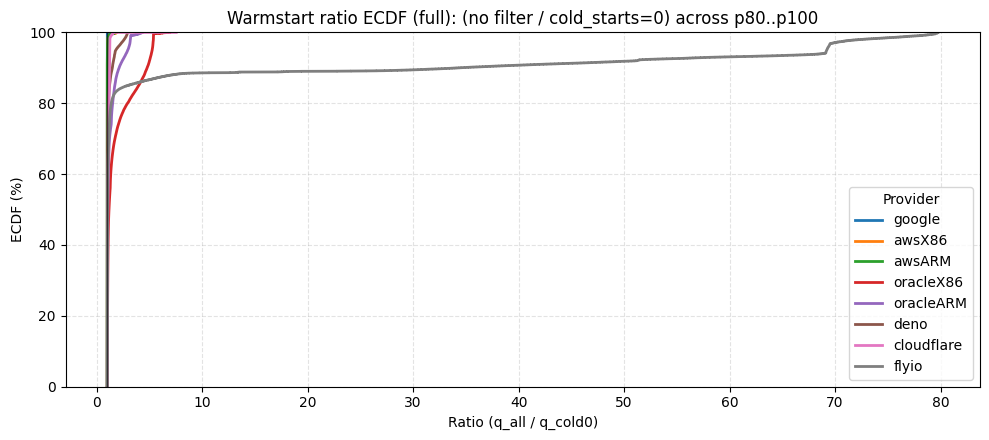

In [12]:
# ECDF of percentile ratios (full y-range): no filter / cold_starts=0 across p80..p100
import numpy as np

# Reuse df_ratio if it exists (from the cell above), otherwise recompute it.
if "df_ratio" not in globals() or df_ratio is None or df_ratio.empty:
    percentiles = np.linspace(0.80, 1.00, 10000)
    rows = []
    for provider in providers:
        df_cold0 = load_warmstart(provider, "cold0")
        df_all = load_warmstart(provider, "all")
        for frame in (df_cold0, df_all):
            frame["http_req_waiting"] = pd.to_numeric(frame["http_req_waiting"], errors="coerce")
        df_cold0 = df_cold0.dropna(subset=["http_req_waiting"])
        df_all = df_all.dropna(subset=["http_req_waiting"])
        df_cold0 = df_cold0[df_cold0["http_req_waiting"] > 0]
        df_all = df_all[df_all["http_req_waiting"] > 0]
        if df_cold0.empty or df_all.empty:
            continue
        q_cold0 = df_cold0["http_req_waiting"].quantile(percentiles).to_numpy()
        q_all = df_all["http_req_waiting"].quantile(percentiles).to_numpy()
        ratio = q_all / q_cold0
        for r in ratio:
            rows.append({"provider": provider, "ratio": r})
    df_ratio = pd.DataFrame(rows)
    df_ratio = df_ratio.replace([np.inf, -np.inf], np.nan).dropna(subset=["ratio"])

if df_ratio.empty:
    print("No data to plot percentile ratio ECDFs.")
else:
    providers_in_plot = [p for p in providers if p in set(df_ratio["provider"]) ]
    if not providers_in_plot:
        print("No provider data to plot percentile ratio ECDFs.")
    else:
        fig, ax = plt.subplots(figsize=(10, 4.5))
        palette = sns.color_palette("tab10", n_colors=len(providers_in_plot))
        palette_map = dict(zip(providers_in_plot, palette))
        for provider in providers_in_plot:
            df_p = df_ratio[df_ratio["provider"] == provider]
            if df_p.empty:
                continue
            sns.ecdfplot(
                data=df_p,
                x="ratio",
                ax=ax,
                linewidth=2,
                color=palette_map[provider],
                label=provider,
                legend=False,
            )
        ax.axvline(1, color="black", linewidth=1, alpha=0.6)
        ax.set_title("Warmstart ratio ECDF (full): (no filter / cold_starts=0) across p80..p100")
        ax.set_xlabel("Ratio (q_all / q_cold0)")
        ax.set_ylabel("ECDF (%)")
        ax.set_ylim(0.0, 1.0)
        ticks = np.linspace(0.0, 1.0, 6)
        ax.set_yticks(ticks)
        ax.set_yticklabels((ticks * 100).astype(int))
        ax.grid(True, linestyle="--", alpha=0.35)
        ax.legend(title="Provider", loc="best")
        plt.tight_layout()
        plt.show()

In [20]:
# Table: cold start share per provider (warmstart)
rows = []
for provider in providers:
    df_counts = pd.read_sql_query(
        """
        SELECT
            COUNT(*) AS n_total,
            SUM(CASE WHEN cold_starts > 0 THEN 1 ELSE 0 END) AS n_cold
        FROM data
        WHERE provider = ?
          AND experiment = 'warmstart'
        """,
        cnx,
        params=[provider],
    )
    n_total = int(df_counts.loc[0, "n_total"] or 0)
    n_cold = int(df_counts.loc[0, "n_cold"] or 0)
    cold_pct = (n_cold / n_total * 100.0) if n_total else float("nan")
    rows.append({
        "provider": provider,
        "n_total": n_total,
        "n_cold": n_cold,
        "cold_pct": cold_pct,
    })

df_cold_share = pd.DataFrame(rows).sort_values("cold_pct", ascending=False)
print(df_cold_share)

     provider  n_total  n_cold   cold_pct
8      fastly   640160  633455  98.952606
6  cloudflare   296889   17846   6.011001
3   oracleX86  1916472   68171   3.557109
7       flyio  1916658   42896   2.238062
4   oracleARM  1914563   28464   1.486710
5        deno   296887    3692   1.243571
1      awsX86  1622160    3382   0.208487
2      awsARM  1919350    3827   0.199390
0      google  1919476     104   0.005418
